# AllRecipes Data Analysis Project

## 1. Introduction
*(We will introduce the data set and our guiding question here.)*

The data for this project comes from Allrecipes, a popular online platform where home cooks and food enthusiasts share and review recipes from around the world (Allrecipes, n.d.). The project comprises two datasets: allrecipes, a general collection of roughly 14,000 recipes spanning a wide range of dish types, cuisines, and a smaller collection of around 2,200 recipes organised by country of origin. For each recipe, the dataset captures a rich set of attributes, including the list of ingredients, nutritional information per serving (calories, fat, carbohydrates, and protein), the time needed to prepare and cook the dish, user ratings, and the number of reviews received (Mubia, 2025). One limitation to note is that review counts for highly popular recipes are truncated at the thousands, so these figures should be treated as approximate for widely-reviewed dishes (Mubia, 2025).

With such a large and varied collection of recipes, a practical question emerges: which recipes are genuinely worth attempting? A dish might earn glowing reviews yet require several hours of work, while another might be quick to make but fail to impress. This project explores the concept of "actionable" recipes, which refer to those that sit at the sweet spot of being both highly rated by users and achievable within a short amount of time. Namely, our question of interest is: Which recipes are the most "actionable" — high rating with low total time? To investigate this, we primarily draw on the general allrecipes dataset, as its substantially larger sample provides a more reliable basis for identifying meaningful patterns. **[TO BE UPDATED: The variables most relevant to this analysis are the average user rating out of five stars (avg_rating) and the total time recorded for each recipe in minutes (total_time), which includes preparation and cooking time but excludes passive waiting periods such as refrigeration, marination, and additional wait times due to inconsistent availability across recipes. We additionally use the number of ratings received (total_ratings) to ensure recipes have sufficient community feedback to be considered reliable, and the recipe name (name) to derive broad recipe categories through keyword extraction.]** By examining how these variables interact across thousands of recipes, we aim to surface patterns that reflect not just what tastes good, but what is realistically appealing for everyday cooking.

## 2. Data Cleaning and Summary
*(We will document our transformations and summary statistics here.)*

### 2.1 Imports

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load data
url_recipes = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-09-16/all_recipes.csv'
url_cuisines = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-09-16/cuisines.csv'

# Turn links into DataFrames
df_recipes = pd.read_csv(url_recipes)
df_cuisines = pd.read_csv(url_cuisines)

df_cuisines.head()

,name,country,url,author,date_published,ingredients,calories,fat,carbs,protein,avg_rating,total_ratings,reviews,prep_time,cook_time,total_time,servings
0,Saganaki (Flaming Greek Cheese),Greek,https://www.allrecipes.com/recipe/263750/flami...,John Mitzewich,2024-02-07,"1 (4 ounce) package kasseri cheese, 1 tablespo...",391.0,25.0,15.0,16.0,4.8,25.0,22.0,10,5,15,2.0
1,Coney Island Knishes,Jewish,https://www.allrecipes.com/recipe/272334/coney...,John Mitzewich,2024-11-26,"2 ¾ cups all-purpose flour, or more as needed,...",301.0,17.0,31.0,7.0,4.6,10.0,9.0,30,75,180,16.0
2,Diana's Hawaiian Bread Rolls,Australian and New Zealander,https://www.allrecipes.com/recipe/22797/dianas...,CHIPPENDALE,2022-07-14,1 ½ cups warm water (110 degrees F/45 degrees ...,64.0,3.0,9.0,1.0,4.3,126.0,104.0,20,15,180,12.0
3,Chilean Pebre,Chilean,https://www.allrecipes.com/recipe/273763/chile...,Heidi,2025-01-31,"½ cup chopped cilantro, ¼ cup olive oil, ¼ cup...",106.0,9.0,7.0,1.0,5.0,1.0,1.0,10,0,10,6.0
4,Tex-Mex Sheet Cake,Tex-Mex,https://www.allrecipes.com/recipe/22388/tex-me...,Ann,2025-02-18,"2 cups all-purpose flour, 1 ½ cups brown sugar...",449.0,23.0,58.0,7.0,3.8,13.0,11.0,30,15,45,15.0


In [3]:
df_recipes.head()

,name,url,author,date_published,ingredients,calories,fat,carbs,protein,avg_rating,total_ratings,reviews,prep_time,cook_time,total_time,servings
0,Chewy Whole Wheat Peanut Butter Brownies,https://www.allrecipes.com/recipe/140717/chewy...,DMOMMY,2020-06-18,"⅓ cup margarine, softened, ⅔ cup white sugar, ...",222.0,13.0,24.0,6.0,4.4,47.0,36.0,20,35,55,16.0
1,Pumpkin Pie Eggnog,https://www.allrecipes.com/recipe/269204/pumpk...,Bobbie Susan,2022-09-26,"12 egg yolks, 2 cups heavy whipping cream, ½ ...",477.0,31.0,43.0,8.0,5.0,1.0,1.0,10,5,495,8.0
2,Eggs Poached in Tomato Sauce,https://www.allrecipes.com/recipe/238054/eggs-...,Bren,2018-06-08,"2 tablespoons olive oil, or to taste, ½ onion...",354.0,18.0,32.0,20.0,4.8,4.0,4.0,10,75,85,4.0
3,Minestrone Casserole,https://www.allrecipes.com/minestrone-casserol...,Sarah Brekke,2025-03-03,4 cups dried mafalda pasta (mini lasagna noodl...,356.0,9.0,53.0,19.0,4.3,14.0,13.0,20,40,60,8.0
4,Yummy Stuffed Peppers,https://www.allrecipes.com/recipe/241937/yummy...,Procrastigirl,2024-12-11,"4 green bell peppers, halved lengthwise and se...",366.0,22.0,23.0,19.0,4.7,84.0,67.0,30,95,125,8.0


### Data cleaning

In [4]:
# Use outer join to merge cuisine labels onto recipes
df = pd.merge(df_recipes, 
              df_cuisines[['url', 'country']].rename(columns={'country': 'cuisine'}), 
              on='url', 
              how='outer')

# Standardize column types to numeric
num_cols = ["calories", "fat", "carbs", "protein", "avg_rating", 
            "total_ratings", "reviews", "prep_time", "cook_time", 
            "total_time", "servings"]

for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop rows missing essential metrics
df.dropna(subset=['name', 'avg_rating', 'ingredients', 'prep_time', 
                  'cook_time', 'total_time'], inplace=True)

# Remove recipes with 0 time
df = df[df['total_time'] > 0]

other than empty ratings, time and ingredients using NA, some names are 'Allrecipes Member' which i think may be the NA values of names

### Feature Engineering

In [5]:
# Count ingredient lines
def count_ingredients(s):
    if pd.isna(s): return 0
    return len([item for item in str(s).split(",") if item.strip()])

df['n_ingredient_lines'] = df['ingredients'].apply(count_ingredients)

In [6]:
# Actionable Score
df_filtered = df[df['total_ratings'] >= 10].copy() # Filter for reliable averages
df_filtered['z_rating'] = stats.zscore(df_filtered['avg_rating'])

df_filtered['z_ingredients'] = stats.zscore(df_filtered['n_ingredient_lines'])
df_filtered['complexity_score'] = df_filtered['z_rating'] - df_filtered['z_ingredients']

df_filtered['z_log_time'] = stats.zscore(np.log1p(df_filtered['total_time']))
df_filtered['action_score'] = df_filtered['z_rating'] - df_filtered['z_log_time']

df_filtered['ultimate_score'] = df_filtered['z_rating'] - (df_filtered['z_log_time'] + df_filtered['z_ingredients'])

### Key summary statistics

In [7]:
print("--- General Dataset Shape ---")
print(f"Total recipes after cleaning: {len(df):,}")
print(f"Recipes with cuisine tags: {df['cuisine'].notna().sum():,}")

print("\n--- Central Tendencies for Time and Complexity ---")
time_stats = df[['prep_time', 'cook_time', 'total_time', 'n_ingredient_lines']].describe().loc[['mean', '50%', 'std']]
display(time_stats)

print("\n--- Cuisine Distribution (Top 10) ---")
display(df['cuisine'].value_counts().head(10))

print("\n--- User Interaction Summary ---")
rating_stats = df[['avg_rating', 'total_ratings']].describe().loc[['mean', '50%', 'max']]
display(rating_stats)

print("\n--- Correlation: Time vs. Rating ---")
corr_time_rating = df[['total_time', 'avg_rating']].corr().iloc[0,1]
print(f"Pearson Correlation between Total Time and Average Rating: {corr_time_rating:.4f}")

print("\n--- Top 5 Fastest High-Rated Recipes (High Rating, Low Time) ---")
display(df_filtered.sort_values('action_score', ascending=False)[['name', 'total_time', 'avg_rating', 'n_ingredient_lines', 'action_score']].head(5))

print("\n--- Correlation: Ingredients vs. Rating ---")
corr_ingredients_rating = df[['n_ingredient_lines', 'avg_rating']].corr().iloc[0,1]
print(f"Pearson Correlation between Total Time and Average Rating: {corr_ingredients_rating:.4f}")

print("--- Top 5: Simplest High-Rated Recipes (Low Ingredients) ---")
display(df_filtered.sort_values('complexity_score', ascending=False)
        [['name', 'avg_rating', 'n_ingredient_lines', 'complexity_score']].head(5))

print("\n--- Correlation: Ingredients vs. Time ---")
complexity_corr = df[['total_time', 'n_ingredient_lines']].corr().iloc[0,1]
print(f"\nCorrelation between Total Time and Number of Ingredients: {complexity_corr:.4f}")

print("\n--- Top 5: Simplest and Fastest High-Rated Recipes (High Rating, Low Time, Low Ingredients) ---")
display(df_filtered.sort_values('ultimate_score', ascending=False)
        [['name', 'avg_rating', 'total_time', 'n_ingredient_lines', 'ultimate_score']].head(5))

--- General Dataset Shape ---
Total recipes after cleaning: 13,104
Recipes with cuisine tags: 1,001

--- Central Tendencies for Time and Complexity ---


,prep_time,cook_time,total_time,n_ingredient_lines
mean,17.790140,44.717415,149.599435,12.390644
50%,15.000000,25.000000,55.000000,11.000000
std,23.601901,99.632413,901.598716,5.725828



--- Cuisine Distribution (Top 10) ---


cuisine
Chinese             64
Indian              64
Jewish              59
Italian             57
Korean              55
Cajun and Creole    53
Tex-Mex             52
Spanish             39
Soul Food           35
French              32
Name: count, dtype: int64


--- User Interaction Summary ---


,avg_rating,total_ratings
mean,4.531219,102.082036
50%,4.600000,26.000000
max,5.000000,997.000000


... (2 outputs left out)


--- Correlation: Ingredients vs. Rating ---
Pearson Correlation between Total Time and Average Rating: 0.0747
--- Top 5: Simplest High-Rated Recipes (Low Ingredients) ---


,name,avg_rating,n_ingredient_lines,complexity_score
10041,Baked Corn Tortilla Strips for Mexican Soups,5.0,3,3.36352
11253,3-Ingredient Whipped Cream,5.0,3,3.36352
2673,Broiler S'mores,5.0,3,3.36352
12139,Microwave Spaghetti Squash,5.0,3,3.36352
9867,Low-Carb Keto Cheese Taco Shells,4.9,1,3.36149



--- Correlation: Ingredients vs. Time ---

Correlation between Total Time and Number of Ingredients: 0.0048

--- Top 5: Simplest and Fastest High-Rated Recipes (High Rating, Low Time, Low Ingredients) ---


,name,avg_rating,total_time,n_ingredient_lines,ultimate_score
14909,Classic White Wine Spritzer,4.9,5.0,2,5.483654
4417,Pumpkin Pie Spice I,4.7,1.0,4,5.442965
2227,Simple Cranberry Spinach Salad,5.0,5.0,5,5.301106
1761,Peach Cosmo,5.0,5.0,5,5.301106
5753,S'mores,4.9,5.0,3,5.299076


#### Additional summary statistics for actionable recipes with other factors like nutritional value, author and engagement (total_reviews)

In [8]:
# 1. Nutritional Profile of Actionable vs. Non-Actionable
# Let's define "Top Actionable" as the top 10% of ultimate_score
top_threshold = df_filtered['ultimate_score'].quantile(0.9)
df_filtered['is_top_actionable'] = df_filtered['ultimate_score'] >= top_threshold

print("--- Nutritional Comparison: Actionable vs. Others ---")
# Do faster, highly-rated recipes have more sugar/fat (calories)?
nutritional_comp = df_filtered.groupby('is_top_actionable')[['calories', 'fat', 'protein']].median()
display(nutritional_comp)

# 2. Author Concentration: Are "Actionable" recipes dominated by specific authors?
print("\n--- Authors of the Most Actionable Recipes ---")
top_authors = df_filtered[df_filtered['is_top_actionable']]['author'].value_counts().head(5)
display(top_authors)

# 3. Review Volatility
# Are "Actionable" recipes more controversial? (Standard deviation of reviews)
print("\n--- Review Engagement by Time Category ---")
df['time_quartile'] = pd.qcut(df['total_time'], 4, labels=['Very Fast', 'Fast', 'Medium', 'Slow'])
engagement = df.groupby('time_quartile', observed=True)['total_ratings'].agg(['mean', 'std'])
display(engagement)

--- Nutritional Comparison: Actionable vs. Others ---


,calories,fat,protein
is_top_actionable,,,
False,317.0,15.0,9.0
True,181.0,9.0,4.0



--- Authors of the Most Actionable Recipes ---


author
John Mitzewich       30
Allrecipes Member    16
France Cevallos      12
Sara                  9
Carol                 7
Name: count, dtype: int64


--- Review Engagement by Time Category ---


,mean,std
time_quartile,,
Very Fast,100.252870,172.070778
Fast,103.902074,176.484700
Medium,110.125816,181.118917
Slow,93.493643,162.234260


The most insightful takeaway is the lack of correlation (r = 0.008 for time and r = 0.0048 for ingredients). This shows that there is no correlation between ratings with time and with ingredients, making the search for actionable recipes valid. 

Another interesting insight is that the most actionable recipe based on time and both time and number of ingredients are drinks and the top 5 actionable recipes can also be seen to contain many drinks. However, the most actionable recipe based on the number of ingredients is food and the top 5 contains mainly food, soup and creams. This suggests that the most actionable recipes are often components (creams) or drinks. 

The fact that actionable recipes have nearly half the calories (181 vs 317) and significantly less fat is a major insight. It suggests that actionable recipes are fast, lighter and potentially healthier. However, this may also be due to the fact that the most actionable recipes are mostly drinks that would usually have less calories, fat and protein compared to food. 

The "Medium" time category actually has the highest mean engagement (110 ratings), while "Slow" has the lowest (93). This suggests that time is a real factor that affects the reader's decision on which recipe to start on. A medium time is preferred by the community as seen by the mean engagement which may mean that the most actionable recipes determined by current readers are those that take "Medium" time. As seen from how our top actionable recipes based on time are mostly drinks, the "Medium" category may have more recipes for food that take less time. Hence, current users may be more attracted to these recipes.

## 3. Visualisation
- Scatter plot: Rating vs. Total Time (using color to separate food and drinks? -> if cannot do this, just note down somewhere that drinks on average take less time)
    - x = total_time, y = avg_rating, one point per recipe
    - With 13,000+ recipes, a standard scatter plot will suffer from overplotting.
    - Improvement: Use Hexbinning or Density Contours. Instead of individual points,
    use a hexbin plot where the color intensity represents the number of recipes.
    - Improvement: Instead of showing all points, draw a line connecting the highest 
    rated recipe at each time interval (Any recipe on or near that line is "The Best 
    of its Class.")
    - The "Actionable" Layer: Overlay a red dashed rectangle in the "High Rating
    (>4.5) / Low Time (<30 mins)" quadrant. This visually defines "Actionable" for
    the reader immediately.
    - Possible: use a Marginal Plot (histograms on the top and side of the scatter 
    plot) to show where the volume of recipes truly sits.
- Box plot: Rating distribution across time buckets
    - Bin total_time into groups (e.g. under 30 min, 30–60 min, 1–2 hrs, 2+ hrs)
    - Show the spread of avg_rating within each bucket
    - Improvement: Add Sample Sizes (N=) above each box. If the "2+ hrs" box is
    based on 200 recipes but the "Under 30 min" box is based on 5,000, your reader
    needs to know the latter is a more "reliable" finding.
    - Improvement: There may be a lot of outliers. Set showfliers=False in Seaborn 
    to hide individual outliers, or use a Violin Plot with a box plot inside it
    - Visual: Use a Notched Box Plot / Violin plot. If the notches of two boxes do
    not overlap, it’s a visual shorthand for saying the difference in their medians
    is statistically significant.
    - Refined Buckets: Instead of quartiles, use "Human" buckets: 0-15m (Ultra-
    Fast), 15-45m (Standard), 45-90m (Slow), 90m+ (Event). This is more relatable to 
    a home cook.
- Heatmap: Time and Ingredients list against rating
    - X-axis: Total Time Bins (e.g., 0-15, 15-30, 30-60, 60+)
    - Y-axis: Ingredient Count Bins (e.g., 1-5, 6-10, 11-15, 16+)
    - Color/Intensity: The Average Rating (or the percentage of recipes that are "5-
    stars" for better color differentiation)
    - The cell in the top-left (Low Time + Low Ingredients) will show a specific color. If that color is "Dark Green" (High Rating), you have visual, empirical proof that simplicity is rewarded.
    - It might show that as you move to the bottom-right (High Time + High Ingredients), the ratings don't actually get higher, proving they aren't "more actionable."

### 3.3 Heatmap

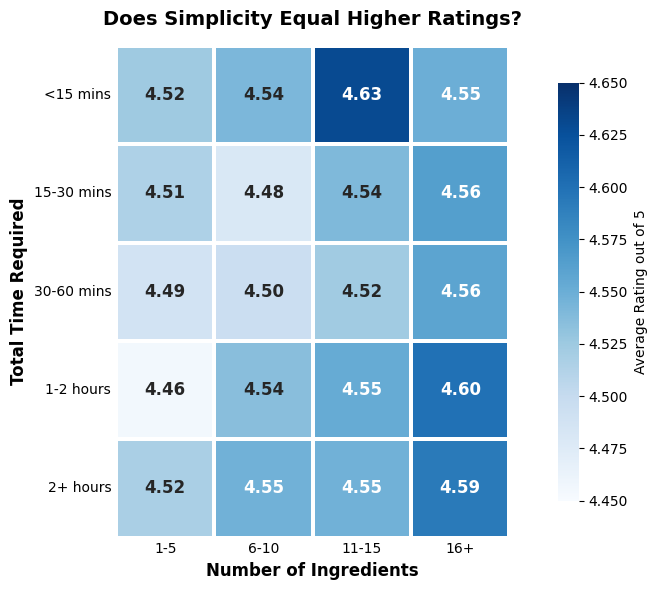

In [ ]:
# Create 'total_time' and 'n_ingredient_lines' buckets
time_bins = [0, 15, 30, 60, 120, np.inf]
time_labels = ['<15 mins', '15-30 mins', '30-60 mins', '1-2 hours', '2+ hours']
df_filtered['time_bucket'] = pd.cut(df_filtered['total_time'], bins = time_bins, labels = time_labels)

ingredient_bins = [0, 5, 10, 15, np.inf]
ingredient_labels = ['1-5', '6-10', '11-15', '16+']
df_filtered['ingredient_bucket'] = pd.cut(df_filtered['n_ingredient_lines'], bins = ingredient_bins, labels = ingredient_labels)

heatmap_data = df_filtered.pivot_table(
    index = 'time_bucket',
    columns = 'ingredient_bucket',
    values = 'avg_rating',
    aggfunc = 'mean'
)

# Plot the Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    heatmap_data,
    annot = True,
    fmt = ".2f",            # 2 decimal places
    cmap = "Blues",         # Darker blue = higher rating
    vmin = 4.45,            
    vmax = 4.65,            
    square = True,          
    linewidths = 1.5,       
    linecolor = 'white',
    annot_kws = {"size": 12, "weight": "bold"},
    cbar_kws = {'label': 'Average Rating out of 5', 'shrink': 0.85}
)
plt.title("Does Simplicity Equal Higher Ratings?", fontsize = 14, fontweight = 'bold', pad = 15)
plt.xlabel("Number of Ingredients", fontsize = 12, fontweight = 'bold')
plt.ylabel("Total Time Required", fontsize = 12, fontweight = 'bold')
plt.yticks(rotation=0)
plt.tick_params(axis='both', which='both', length=0)
plt.tight_layout()
plt.show()

This heatmap visualises the intersection of effort (Total Time) and complexity (Number of Ingredients) to test the hypothesis that simple, fast recipes are the most "actionable" and highly rated. 

Interestingly, the data contradicts this assumption. While fast recipes generally perform well, simplicity (1-5 ingredients) yields the lowest ratings across almost all time brackets, with the lowest being 4.46 for 1-2 hour recipes. Instead, the platform rewards flavour complexity. The highest-rated recipes involve 11-15 or 16+ ingredients, regardless of how long they take to cook. 

The "actionable" sweet spot is found in the top-right quadrant (under 15 minutes, 11-15 ingredients, peaking at 4.63), suggesting that home cooks highly value quick-assembly dishes that do not compromise on complex, ingredient-dense flavour profiles.

## 4. Discussions
*(We will explain the insights from our plots here.)*

## 5. Teamwork
*(Tasks allocation paragraph goes here.)*

## 6. References
* TidyTuesday AllRecipes Dataset: https://github.com/rfordatascience/tidytuesday/blob/main/data/2025/2025-09-16/readme.md
* Mubia, B. (2025, September 16). Allrecipes [Data set]. TidyTuesday. https://github.com/rfordatascience/tidytuesday/blob/main/data/2025/2025-09-16/readme.md